# 08 — NOx (EMG) retrieval error via Monte-Carlo parameter sampling

Propagates injection-pressure, fire-centroid, analyst-choice, and **pixel-bootstrap** uncertainty through the EMG NOx retrieval. Reports a single combined distribution for **E(NOx)** and **τ**.

**Plume-alignment gate:** each member's sampled injection pressure gives a wind direction θ_wind. An AI-weighted PCA on the AER_AI plume pixels within `PCA_RADIUS_KM` of the *sampled* centroid gives the observed transport axis θ_plume. Members with |θ_wind − θ_plume| > `MAX_WIND_PLUME_ANGLE_DEG` are rejected as physically inconsistent and logged as controlled failures. The PCA is recomputed per member because the centroid is sampled from a KDE.

Every fit diagnostic (`x0`, `r2`, `cv_E`, `peak_x_km`, `fit_stable`) is still logged for post-hoc inspection.

In [1]:
# ── Monte-Carlo error-estimation parameters (sampled ranges agreed in brainstorm) ─
N_SAMPLES: int = 500
SEED: int      = 42

FIRE_DATE  = "2026-01-18"
TARGET_DAY = "".join(FIRE_DATE.split("-")[1:])  # "0118"

# Analyst-choice sample ranges
AI_THRESHOLDS    = [2.0]   # discrete; also selects the pressure KDE
QA_LEVELS_UINT8  = [50]                        # qa_value cut (loader uses uint8 0-100)

# Injection-pressure KDE (matched AER_LH pixels)
PRESS_RADIUS_KM    = 450.0
PRESS_MIN_PIXELS   = 15

# Centroid KDE (FRP-weighted MODIS), recentered on the retrieval centroid
CENTROID_LOCAL_RADIUS_KM = 200.0
CENTROID_MIN_CONF        = 75
CENTROID_SAT             = "Aqua"
CENTROID_DAYNIGHT        = "D"

# Fail-loud control: raised from 0.25 to accommodate the alignment gate, which
# intentionally rejects ~30% of members on physical grounds.
MAX_FAIL_FRACTION = 0.50

# NOx-specific ranges
NOX_NO2_RATIO_GAMMA      = 1.32     # Jin et al. (2021), held fixed
NO2_MOLAR_MASS_G_PER_MOL = 46.005
DOWNWIND_MIN_KM   = -100.0
DOWNWIND_MAX_RANGE = (400.0, 500.0)
CROSSWIND_RANGE    = (80.0, 120.0)
GRID_DY_CHOICES    = [0.05]   # deg; converted to km below
EXTRACTION_RADIUS_RANGE = (400.0, 500.0)
BOOTSTRAP_ITERS    = 20
DEG_TO_KM          = 111.32

# Physical lower bound on the EMG decay length x0 (km).
# Set to the grid cell size: you cannot fit a decay shorter than one grid cell.
MIN_X0_KM: float = GRID_DY_CHOICES[0] * DEG_TO_KM  # 0.05° × 111.32 ≈ 5.57 km

# ── Plume-alignment gate ──────────────────────────────────────────────────────
# Parameters (PCA radius, far-field distance, 15° threshold, minimum pixel counts)
# live in config/mc_alignment_gate.yaml and are loaded below with the gate code
# (src.error_estimation.plume_axis_pca / angular_diff_deg), shared with the other MC notebook.

In [2]:
import sys, glob, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shapely
warnings.filterwarnings("ignore")  # KDE/curve_fit chatter; failures are still raised explicitly

ROOT = Path(".").resolve()
while not ((ROOT / "src").exists() and (ROOT / "data").exists()):
    if ROOT == ROOT.parent:
        raise RuntimeError("Could not locate project root (need src/ and data/).")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import error_estimation as ee
from src import plume_helpers as ph
from src.data_helpers import (load_co_l2, load_no2_l2, load_aer_ai,
                              load_aer_lh, get_modis_hotspot)

DATA = ROOT / "data"
ERA5_PL = DATA / "ERA5_winds_pressure_levels.nc"
MODIS_CSV = DATA / "fire_nrt_M-C61_723973.csv"
HOTSPOT_CSV = DATA / "daily_dominant_hotspot_summary.csv"
QA_BASE = 50

# Wide loader domain (matches the science notebooks)
LAT_MIN, LAT_MAX = -66.83, -6.83
LON_MIN, LON_MAX = -103.05, -43.05

modis = get_modis_hotspot(HOTSPOT_CSV, FIRE_DATE,
                          lat_min=LAT_MIN, lat_max=LAT_MAX, lon_min=LON_MIN, lon_max=LON_MAX)
FIRE_LAT = float(modis["dominant_lat"].values[0])
FIRE_LON = float(modis["dominant_lon"].values[0])
print(f"Retrieval centroid: ({FIRE_LAT:.4f}, {FIRE_LON:.4f})  FRP={modis['dominant_frp_mw'].values[0]} MW")

def _load_and_concat(paths, loader, **kwargs):
    chunks, scal = defaultdict(list), {}
    for p in paths:
        d = loader(Path(p), **kwargs)
        if d is None:
            continue
        for k, v in d.items():
            (chunks[k].append(v) if isinstance(v, np.ndarray) else scal.__setitem__(k, v))
    out = {k: np.concatenate(v) for k, v in chunks.items()}; out.update(scal)
    return out

roi_kwargs = dict(lat_min=LAT_MIN, lat_max=LAT_MAX, lon_min=LON_MIN, lon_max=LON_MAX, qa_threshold=QA_BASE)
ai_base = _load_and_concat(
    sorted(glob.glob(str(DATA/TARGET_DAY/"S5P_OFFL_L2__AER_AI_2026*"))), load_aer_ai, **roi_kwargs)

# ── Plume boundary: clip AI outside the saved blob-clustered inclusion
# geometry down below threshold, replacing the previous ad hoc "lon > -72"
# clip. Downstream AI>threshold tests (pressure KDE, PCA pre-filter) become
# boundary-consistent automatically.
PLUME_BOUNDARY_PATH = DATA / TARGET_DAY / "plume_boundary.geojson"
plume_boundary = ph.load_plume_boundary(PLUME_BOUNDARY_PATH)
AI_THRESHOLD_BOUNDARY = plume_boundary.threshold
_in_boundary = shapely.contains_xy(plume_boundary.boundary, ai_base["lon"], ai_base["lat"])
ai_base["ai"] = np.where(_in_boundary, ai_base["ai"],
                         np.minimum(ai_base["ai"], AI_THRESHOLD_BOUNDARY - 1e-3))
print(f"Plume boundary: {plume_boundary.boundary.geom_type}  threshold={AI_THRESHOLD_BOUNDARY:.3f}  "
      f"({int(_in_boundary.sum())}/{_in_boundary.size} AER_AI pixels inside boundary)")
assert len(AI_THRESHOLDS) == 1 and abs(AI_THRESHOLDS[0] - AI_THRESHOLD_BOUNDARY) < 1e-6, (
    f"AI_THRESHOLDS={AI_THRESHOLDS} no longer matches the boundary threshold "
    f"{AI_THRESHOLD_BOUNDARY} — update AI_THRESHOLDS or re-check the boundary file."
)

alh_base = _load_and_concat(
    sorted(glob.glob(str(DATA/TARGET_DAY/"S5P_OFFL_L2__AER_LH_2026*"))), load_aer_lh, **roi_kwargs)

# ── Injection-pressure KDE per AI threshold (so AI threshold is a live parameter) ─
pressure_kdes = {}
for thr in AI_THRESHOLDS:
    try:
        pk = ee.build_pressure_kde(ai_base["ai"], ai_base["lat"], ai_base["lon"],
                                   alh_base["alh_pres"], alh_base["lat"], alh_base["lon"],
                                   FIRE_LAT, FIRE_LON, ai_threshold=thr,
                                   radius_km=PRESS_RADIUS_KM, min_pixels=PRESS_MIN_PIXELS)
        pressure_kdes[thr] = pk
    except ValueError as e:
        print(f"  AI thr {thr}: pressure KDE skipped ({e})")
AVAILABLE_AI = sorted(pressure_kdes)
assert AVAILABLE_AI, "No AI threshold yielded a valid pressure KDE."
print(f"AI thresholds with a pressure KDE: {AVAILABLE_AI}")
for thr in AVAILABLE_AI:
    pk = pressure_kdes[thr]
    print(f"  thr {thr}: n={pk['n']:3d}  median={pk['median_hpa']:.0f} hPa  IQR={pk['iqr_hpa']:.0f}")

# ── Centroid KDE (recentered on the retrieval centroid, keep KDE spread) ──────
ck = ee.build_centroid_kde(MODIS_CSV, FIRE_DATE, FIRE_LAT, FIRE_LON,
                           local_radius_km=CENTROID_LOCAL_RADIUS_KM,
                           min_confidence=CENTROID_MIN_CONF,
                           satellite=CENTROID_SAT, daynight=CENTROID_DAYNIGHT)
_cs = ck["kde"].resample(5000, seed=SEED)
CENTROID_DLAT = FIRE_LAT - float(_cs[0].mean())
CENTROID_DLON = FIRE_LON - float(_cs[1].mean())
print(f"Centroid KDE: n={ck['n']}, recenter shift = ({CENTROID_DLAT:+.3f}, {CENTROID_DLON:+.3f})")

# ── ERA5 pressure-level wind slice at overpass ───────────────────────────────
# TROPOMI ascending-node crossing is 13:30 local solar time -> UTC = 13.5 - lon/15
OVERPASS = pd.Timestamp(FIRE_DATE) + pd.Timedelta(hours=13.5 - FIRE_LON/15.0)
era5 = ee.load_era5_pl_slice(ERA5_PL, OVERPASS)
print(f"ERA5 slice: {era5.selected_time}  ({len(era5.p_sorted)} levels)")

# ── Pre-filter plume pixels for per-member PCA ───────────────────────────────
# Keep only pixels above the AI threshold once — the plume-boundary clip is
# already applied to ai_base above, so out-of-boundary pixels are excluded
# automatically. Per-member PCA then only needs to compute distances within
# this small set.
_pca_pre = ai_base["ai"] > min(AI_THRESHOLDS)
PLUME_LAT_PCA = ai_base["lat"][_pca_pre]
PLUME_LON_PCA = ai_base["lon"][_pca_pre]
PLUME_AI_PCA  = ai_base["ai"][_pca_pre]
print(f"Pre-filtered plume pixels for per-member PCA: {_pca_pre.sum():,}  (AI > {min(AI_THRESHOLDS)})")

# ── Plume-alignment gate: shared implementation + config ─────────────────────
GATE = ee.load_alignment_gate_config(ROOT / "config" / "mc_alignment_gate.yaml")
PCA_RADIUS_KM            = GATE["pca_radius_km"]
FAR_FIELD_MIN_KM         = GATE["far_field_min_km"]
MAX_WIND_PLUME_ANGLE_DEG = GATE["max_wind_plume_angle_deg"]
GATE_PCA_KW = dict(radius_km=PCA_RADIUS_KM, far_field_min_km=FAR_FIELD_MIN_KM,
                   min_pixels=GATE["min_pca_pixels"], min_far_pixels=GATE["min_far_field_pixels"])
print(f"Alignment gate: {GATE}")

Retrieval centroid: (-37.5484, -72.5545)  FRP=953.6838 MW
Plume boundary: MultiPolygon  threshold=2.000  (2764/1050159 AER_AI pixels inside boundary)


AI thresholds with a pressure KDE: [2.0]
  thr 2.0: n= 99  median=898 hPa  IQR=73
Centroid KDE: n=146, recenter shift = (-0.491, +0.196)


ERA5 slice: 2026-01-18 18:00:00  (13 levels)
Pre-filtered plume pixels for per-member PCA: 2,096  (AI > 2.0)
Alignment gate: {'pca_radius_km': 450.0, 'far_field_min_km': 150.0, 'max_wind_plume_angle_deg': 15.0, 'min_pca_pixels': 20, 'min_far_field_pixels': 3}


In [3]:
# ── Central retrieval values from the canonical notebook 03 results ──
_RETR_DIR = ROOT / "outputs" / "retrievals" / "0118"
_nox_res = pd.read_csv(_RETR_DIR / "nox_retrieval.csv", index_col=0)["value"]
NOX_REF_GS = float(_nox_res["nox_flux_g_s"])
TAU_REF_H  = float(_nox_res["nox_tau_h"])
print(f"Central NOx retrieval (nb03): {NOX_REF_GS:.0f} g/s, tau={TAU_REF_H:.2f} h")

Central NOx retrieval (nb03): 8415 g/s, tau=0.75 h


In [4]:
# ── Load NO2 L2 flat pixels at both QA levels (all overpasses, concatenated) ─
no2_by_qa = {}
for qa in QA_LEVELS_UINT8:
    no2_by_qa[qa] = _load_and_concat(
        sorted(glob.glob(str(DATA/TARGET_DAY/"S5P_OFFL_L2__NO2____2026*"))), load_no2_l2,
        lat_min=LAT_MIN, lat_max=LAT_MAX, lon_min=LON_MIN, lon_max=LON_MAX, qa_threshold=qa)
    print(f"qa={qa}: {len(no2_by_qa[qa]['no2']):,} NO2 pixels")
OUT_DIR = ROOT / "outputs" / "error_mc" / TARGET_DAY
OUT_DIR.mkdir(parents=True, exist_ok=True)


qa=50: 1,043,829 NO2 pixels


In [5]:
# ── Draw the parameter samples (one row per member) ──────────────────────────
rng = np.random.default_rng(SEED)

# AI threshold (discrete, among those with a valid pressure KDE)
samp_ai = rng.choice(AVAILABLE_AI, size=N_SAMPLES)

# Injection pressure: sample from the AI-threshold-matched KDE, clip to ERA5 range
p_lo, p_hi = float(era5.p_sorted.min()), float(era5.p_sorted.max())
samp_pressure = np.empty(N_SAMPLES)
for thr in AVAILABLE_AI:
    m = samp_ai == thr
    if m.any():
        draw = pressure_kdes[thr]["kde"].resample(int(m.sum()), seed=int(rng.integers(1e9))).flatten()
        samp_pressure[m] = np.clip(draw, p_lo, p_hi)

# Centroid: recentered KDE draws
_cdraw = ck["kde"].resample(N_SAMPLES, seed=SEED + 1)
samp_lat = _cdraw[0] + CENTROID_DLAT
samp_lon = _cdraw[1] + CENTROID_DLON

# QA level
samp_qa = rng.choice(QA_LEVELS_UINT8, size=N_SAMPLES)

# NOx analyst-choice draws
samp_dwmax   = rng.uniform(*DOWNWIND_MAX_RANGE, size=N_SAMPLES)
samp_cross   = rng.uniform(*CROSSWIND_RANGE, size=N_SAMPLES)
samp_gridd   = rng.choice(GRID_DY_CHOICES, size=N_SAMPLES)
samp_radius  = rng.uniform(*EXTRACTION_RADIUS_RANGE, size=N_SAMPLES)
print(f"Drew {N_SAMPLES} parameter sets.")

Drew 500 parameter sets.


In [6]:
# ── Monte-Carlo loop (pixel bootstrap inside each member) ────────────────────
records, fails = [], []
for i in range(N_SAMPLES):
    no2 = no2_by_qa[int(samp_qa[i])]
    u, v, spd, theta = ee.wind_from_pressure(era5, float(samp_lat[i]), float(samp_lon[i]), float(samp_pressure[i]))
    grid_dy_km = float(samp_gridd[i]) * DEG_TO_KM
    row = dict(member=i, pressure_hpa=float(samp_pressure[i]),
               fire_lat=float(samp_lat[i]), fire_lon=float(samp_lon[i]),
               ai_threshold=float(samp_ai[i]), qa=int(samp_qa[i]),
               grid_dy_deg=float(samp_gridd[i]), downwind_max_km=float(samp_dwmax[i]),
               crosswind_km=float(samp_cross[i]), extraction_radius_km=float(samp_radius[i]),
               wind_speed=spd)
    try:
        # ── Plume-alignment gate ──────────────────────────────────────────────
        # PCA is recomputed at the sampled centroid so the pixel set reflects
        # the centroid draw, not the canonical fire location.
        theta_plume = ee.plume_axis_pca(float(samp_lat[i]), float(samp_lon[i]),
                                          PLUME_LAT_PCA, PLUME_LON_PCA, PLUME_AI_PCA, **GATE_PCA_KW)
        delta_theta = ee.angular_diff_deg(theta, theta_plume)
        row["theta_wind_deg"]  = float(np.degrees(theta))
        row["theta_plume_deg"] = float(np.degrees(theta_plume))
        row["delta_theta_deg"] = delta_theta
        if delta_theta > MAX_WIND_PLUME_ANGLE_DEG:
            raise ValueError(
                f"Wind/plume misalignment: Δθ={delta_theta:.1f}° > "
                f"{MAX_WIND_PLUME_ANGLE_DEG}°  "
                f"(θ_wind={np.degrees(theta):.1f}°, "
                f"θ_plume={np.degrees(theta_plume):.1f}°, "
                f"p={float(samp_pressure[i]):.0f} hPa)"
            )
        # ── EMG retrieval ─────────────────────────────────────────────────────
        r = ee.nox_flux_member(no2["lat"], no2["lon"], no2["no2"],
                               float(samp_lat[i]), float(samp_lon[i]), u, v, spd,
                               extraction_radius_km=float(samp_radius[i]),
                               downwind_min_km=DOWNWIND_MIN_KM, downwind_max_km=float(samp_dwmax[i]),
                               crosswind_km=float(samp_cross[i]), grid_dy_km=grid_dy_km,
                               nox_no2_ratio_gamma=NOX_NO2_RATIO_GAMMA,
                               no2_molar_mass_g_per_mol=NO2_MOLAR_MASS_G_PER_MOL,
                               rng=rng, bootstrap_iters=BOOTSTRAP_ITERS,
                               min_x0_km=MIN_X0_KM)
        row.update(r); records.append(row)
    except (ValueError, RuntimeError) as e:
        row["error"] = str(e); fails.append(row)

df = pd.DataFrame(records)
fail_frac = len(fails) / N_SAMPLES
print(f"Converged: {len(df)}/{N_SAMPLES}  (failures: {len(fails)}, {fail_frac:.1%})")
if fails:
    fail_df = pd.DataFrame(fails)
    n_align = fail_df["error"].str.contains("misalignment", na=False).sum()
    n_pca   = fail_df["error"].str.contains("PCA:", na=False).sum()
    n_emg   = len(fails) - n_align - n_pca
    print(f"  alignment gate : {n_align} ({n_align/N_SAMPLES:.1%})")
    print(f"  PCA failure    : {n_pca}")
    print(f"  EMG failure    : {n_emg}")
assert fail_frac <= MAX_FAIL_FRACTION, (
    f"Failure fraction {fail_frac:.1%} exceeds MAX_FAIL_FRACTION={MAX_FAIL_FRACTION:.0%}.")

Converged: 285/500  (failures: 215, 43.0%)
  alignment gate : 213 (42.6%)
  PCA failure    : 0
  EMG failure    : 2


In [7]:
# ── Combined distributions: E(NOx) and tau ───────────────────────────────────
summ_E = ee.summarize(df["E_nox_g_per_s"].to_numpy(), "E(NOx)", "g/s")
summ_T = ee.summarize(df["tau_h"].to_numpy(), "tau", "h")
for s, ref in [(summ_E, f"{NOX_REF_GS:.0f} g/s"), (summ_T, f"{TAU_REF_H:.2f} h")]:
    print(f"{s['name']:8s}: median={s['median']:.3g} {s['unit']}  "
          f"95% CI=[{s['p2_5']:.3g}, {s['p97_5']:.3g}]  ±{s['rel_err_pct']:.0f}%   (ref {ref})")
print(f"\nE(NOx) t/day: median={summ_E['median']*86400/1e6:.1f}  "
      f"[{summ_E['p2_5']*86400/1e6:.1f}, {summ_E['p97_5']*86400/1e6:.1f}]")

E(NOx)  : median=7.5e+03 g/s  95% CI=[3.62e+03, 9.66e+03]  ±40%   (ref 8415 g/s)
tau     : median=0.897 h  95% CI=[0.7, 1.86]  ±65%   (ref 0.75 h)

E(NOx) t/day: median=648.4  [312.8, 834.2]


In [8]:
# ── Export canonical NOx flux distribution (consumed by 09) ──────────
_RETR_DIR = ROOT / "outputs" / "retrievals" / "0118"
_RETR_DIR.mkdir(parents=True, exist_ok=True)
_v = df["E_nox_g_per_s"].to_numpy(); _v = _v[np.isfinite(_v)]
_dist = {
    "species": "NOx", "units": "g/s", "n": int(_v.size),
    "mean": float(_v.mean()), "std": float(_v.std()), "median": float(np.median(_v)),
    "p16": float(np.percentile(_v, 16)), "p84": float(np.percentile(_v, 84)),
    "p2_5": float(np.percentile(_v, 2.5)), "p97_5": float(np.percentile(_v, 97.5)),
}
pd.Series(_dist).to_csv(_RETR_DIR / "nox_distribution.csv", header=["value"])
print(f"Wrote nox_distribution.csv: mean={_dist['mean']:.1f}+/-{_dist['std']:.1f} g/s, "
      f"median={_dist['median']:.1f}, 1sigma[p16,p84]=[{_dist['p16']:.1f},{_dist['p84']:.1f}]")

Wrote nox_distribution.csv: mean=7367.6+/-4061.7 g/s, median=7505.0, 1sigma[p16,p84]=[5262.7,8701.2]


In [9]:
# ── Fit-quality diagnostic (logged, NOT gated) ───────────────────────────────
# Quantifies the degenerate-fit tail so it can be filtered during reanalysis.
deg = df["x0_km"] < 5.0
print(f"Members with collapsed x0 (<5 km): {int(deg.sum())} ({deg.mean():.1%})")
print(f"fit_stable (cv_E<=0.5): {df['fit_stable'].mean():.1%} | peak_within_30km: {df['peak_within_30km'].mean():.1%}")
print(f"r2 percentiles [5,50,95]: {np.round(np.percentile(df['r2'], [5,50,95]), 3)}")
gated = df[(df["x0_km"].between(5, 200)) & (df["r2"] >= 0.7)]
if len(gated) > 10:
    gE = ee.summarize(gated["E_nox_g_per_s"].to_numpy(), "E(NOx) gated", "g/s")
    gT = ee.summarize(gated["tau_h"].to_numpy(), "tau gated", "h")
    print(f"\n[post-hoc gated, n={len(gated)}] E median={gE['median']:.0f} CI=[{gE['p2_5']:.0f},{gE['p97_5']:.0f}]"
          f" | tau median={gT['median']:.2f} CI=[{gT['p2_5']:.2f},{gT['p97_5']:.2f}]")

Members with collapsed x0 (<5 km): 0 (0.0%)
fit_stable (cv_E<=0.5): 100.0% | peak_within_30km: 9.5%
r2 percentiles [5,50,95]: [0.835 0.912 0.929]

[post-hoc gated, n=283] E median=7510 CI=[3644,9659] | tau median=0.90 CI=[0.70,1.77]


In [10]:
# ── Tornado for E(NOx) and tau ───────────────────────────────────────────────
input_cols = ["pressure_hpa", "fire_lat", "fire_lon", "ai_threshold", "qa",
              "grid_dy_deg", "downwind_max_km", "crosswind_km", "extraction_radius_km"]
tor_E = ee.tornado_sensitivity(df[input_cols], df["E_nox_g_per_s"].to_numpy(), "E(NOx)")
tor_T = ee.tornado_sensitivity(df[input_cols], df["tau_h"].to_numpy(), "tau")
print("E(NOx) tornado:\n", tor_E.to_string(index=False))
print("\ntau tornado:\n", tor_T.to_string(index=False))

E(NOx) tornado:
            parameter  spearman      std_beta  abs_std_beta  var_share_pct
            fire_lat -0.234073 -3.461880e-01  3.461880e-01   5.953910e+01
            fire_lon -0.024589 -2.315800e-01  2.315800e-01   2.664283e+01
        pressure_hpa  0.230364  1.180611e-01  1.180611e-01   6.924550e+00
     downwind_max_km  0.000415  1.138019e-01  1.138019e-01   6.433942e+00
extraction_radius_km -0.006998 -2.305532e-02  2.305532e-02   2.640709e-01
        crosswind_km -0.052199  1.983817e-02  1.983817e-02   1.955155e-01
         grid_dy_deg       NaN -1.332268e-15  1.332268e-15   8.817817e-28

tau tornado:
            parameter  spearman      std_beta  abs_std_beta  var_share_pct
        pressure_hpa -0.110350 -2.385192e-01  2.385192e-01   4.067666e+01
            fire_lon -0.021084  2.227947e-01  2.227947e-01   3.549019e+01
            fire_lat  0.352188  1.354702e-01  1.354702e-01   1.312158e+01
        crosswind_km  0.095645  1.168902e-01  1.168902e-01   9.769116e+00
     d

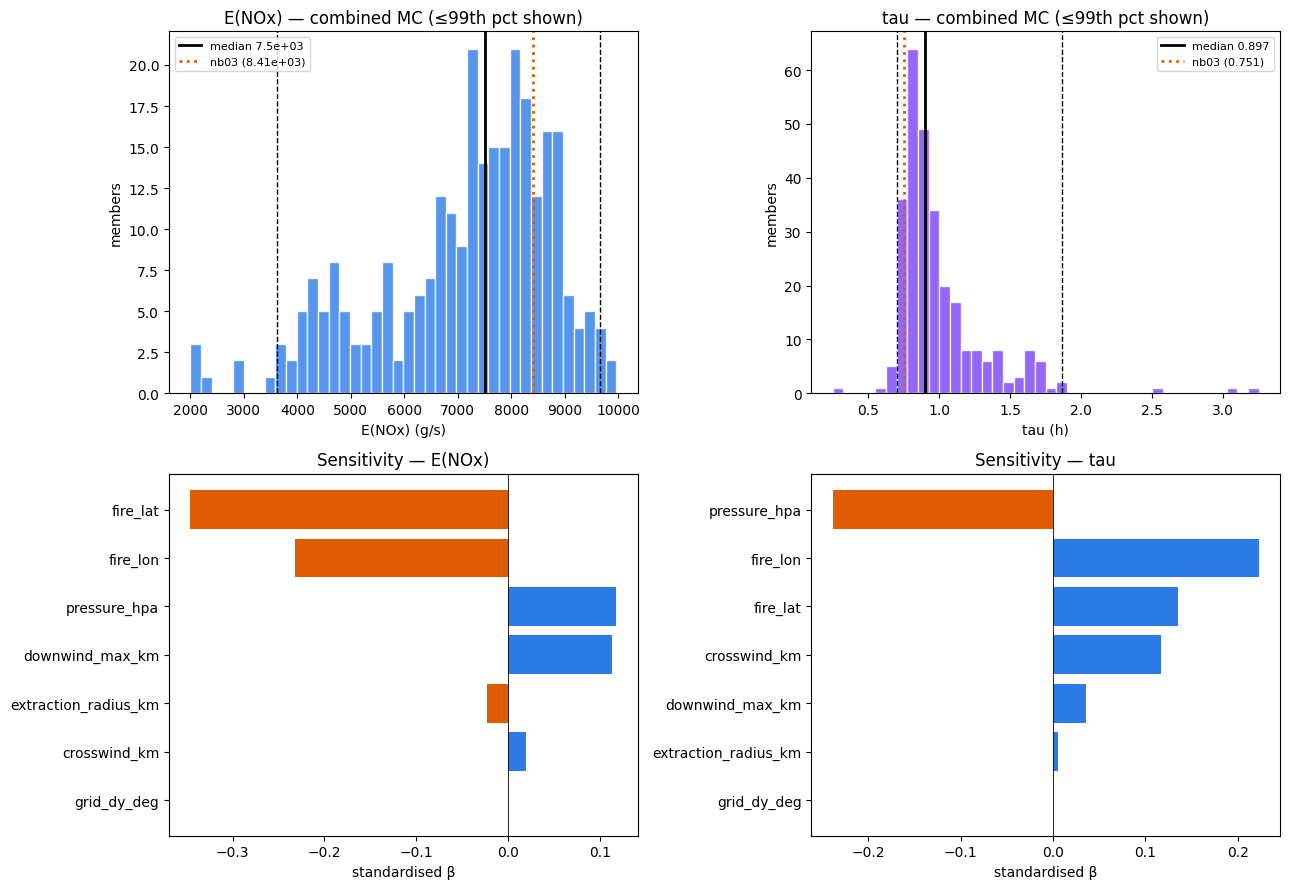

Saved: /Users/maperezc/Downloads/wildfires/outputs/error_mc/0118/nox_error_mc.png


In [11]:
# ── Figures ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col, s, ref, c0 in [
    (axes[0,0], "E_nox_g_per_s", summ_E, NOX_REF_GS, "#2c7be5"),
    (axes[0,1], "tau_h", summ_T, TAU_REF_H, "#7a42f4")]:
    d = df[col]
    q99 = np.percentile(d, 99)
    ax.hist(d[d <= q99], bins=40, color=c0, alpha=0.8, edgecolor="white")
    ax.axvline(s["median"], color="k", lw=2, label=f"median {s['median']:.3g}")
    ax.axvline(s["p2_5"], color="k", ls="--", lw=1); ax.axvline(s["p97_5"], color="k", ls="--", lw=1)
    ax.axvline(ref, color="#e05c00", ls=":", lw=2, label=f"nb03 ({ref:.3g})")
    ax.set(xlabel=f"{s['name']} ({s['unit']})", ylabel="members",
           title=f"{s['name']} — combined MC (≤99th pct shown)")
    ax.legend(fontsize=8)
for ax, tor in [(axes[1,0], tor_E), (axes[1,1], tor_T)]:
    t = tor.iloc[::-1]
    ax.barh(t["parameter"], t["std_beta"], color=np.where(t["std_beta"] >= 0, "#2c7be5", "#e05c00"))
    ax.axvline(0, color="k", lw=0.6)
    ax.set(xlabel="standardised β", title=f"Sensitivity — {tor.attrs['output_name']}")
fig.tight_layout()
fig.savefig(OUT_DIR / "nox_error_mc.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR/'nox_error_mc.png'}")

In [12]:
# ── Persist ──────────────────────────────────────────────────────────────────
import json
df.to_csv(OUT_DIR / "nox_error_members.csv", index=False)
tor_E.to_csv(OUT_DIR / "nox_error_tornado_E.csv", index=False)
tor_T.to_csv(OUT_DIR / "nox_error_tornado_tau.csv", index=False)
with open(OUT_DIR / "nox_error_summary.json", "w") as f:
    json.dump({"E_nox": summ_E, "tau": summ_T, "n_samples": N_SAMPLES, "n_fail": len(fails),
               "reference_E_gs": NOX_REF_GS, "reference_tau_h": TAU_REF_H}, f, indent=2)
print("Wrote nox_error_members.csv, nox_error_tornado_{E,tau}.csv, nox_error_summary.json")

Wrote nox_error_members.csv, nox_error_tornado_{E,tau}.csv, nox_error_summary.json
